In [1]:
# Jalankan sekali jika dependensi belum tersedia
%pip install -q kagglehub tensorflow scikit-learn seaborn


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

SEED = 42
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)

I0000 00:00:1794801422.445141    5114 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794801433.601885    5114 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794801442.374274    5114 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow: 2.22.0-rc0


In [3]:
import kagglehub

# Mengunduh dataset Flowers Recognition dari Kaggle
DATASET_DIR = Path(kagglehub.dataset_download("alxmamaev/flowers-recognition"))
print("Lokasi dataset:", DATASET_DIR)

# Menemukan direktori utama yang berisi sub-folder tiap kelas gambar
image_exts = {".jpg", ".jpeg", ".png"}
class_dirs = sorted([
    d for d in DATASET_DIR.rglob("*")
    if d.is_dir() and any(f.suffix.lower() in image_exts for f in d.iterdir())
])

if not class_dirs:
    raise FileNotFoundError("Folder kelas citra tidak ditemukan pada dataset Kaggle.")

DATA_ROOT = class_dirs[0].parent
CLASS_NAMES = sorted([d.name for d in DATA_ROOT.iterdir() if d.is_dir()])

print("Direktori root citra:", DATA_ROOT)
print("Daftar kelas:", CLASS_NAMES)
print("Jumlah kelas:", len(CLASS_NAMES))

/usr/local/python/3.14.2/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 225M/225M [00:11<00:00, 20.0MB/s] 

Extracting files...


Lokasi dataset: /home/codespace/.cache/kagglehub/datasets/alxmamaev/flowers-recognition/versions/2
Direktori root citra: /home/codespace/.cache/kagglehub/datasets/alxmamaev/flowers-recognition/versions/2/flowers
Daftar kelas: ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']
Jumlah kelas: 5


In [4]:
# Membagi dataset menjadi Training (80%), Validasi (10%), dan Testing (10%)
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_ROOT,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
)

val_test_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_ROOT,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
)

val_batches = tf.data.experimental.cardinality(val_test_ds)
test_ds = val_test_ds.take(val_batches // 2)
val_ds = val_test_ds.skip(val_batches // 2)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

# Ekstraksi array X_test dan y_test agar evaluasi metrik konsisten
X_test_list, y_test_list = [], []
for images, labels in test_ds:
    X_test_list.append(images.numpy())
    y_test_list.append(labels.numpy())

X_test = np.concatenate(X_test_list, axis=0)
y_test = np.concatenate(y_test_list, axis=0)

print(f"Ukuran data test: {X_test.shape}, label test: {y_test.shape}")

Found 4317 files belonging to 5 classes.
Using 3454 files for training.
Found 4317 files belonging to 5 classes.
Using 863 files for validation.


E0000 00:00:1794801649.931844    5114 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



Ukuran data test: (416, 128, 128, 3), label test: (416,)


W0000 00:00:1794801656.252525    7251 cache_dataset_ops.cc:956] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`, or if downstream operations drop elements (e.g. `batch(drop_remainder=True)`). You should use `dataset.take(k).cache().repeat()` instead, or ensure the dataset size is a multiple of the batch size before caching. Another common workaround is to place the `.cache()` operation after the operation that drops elements (like `.batch(...)`), if caching the transformed data is acceptable.


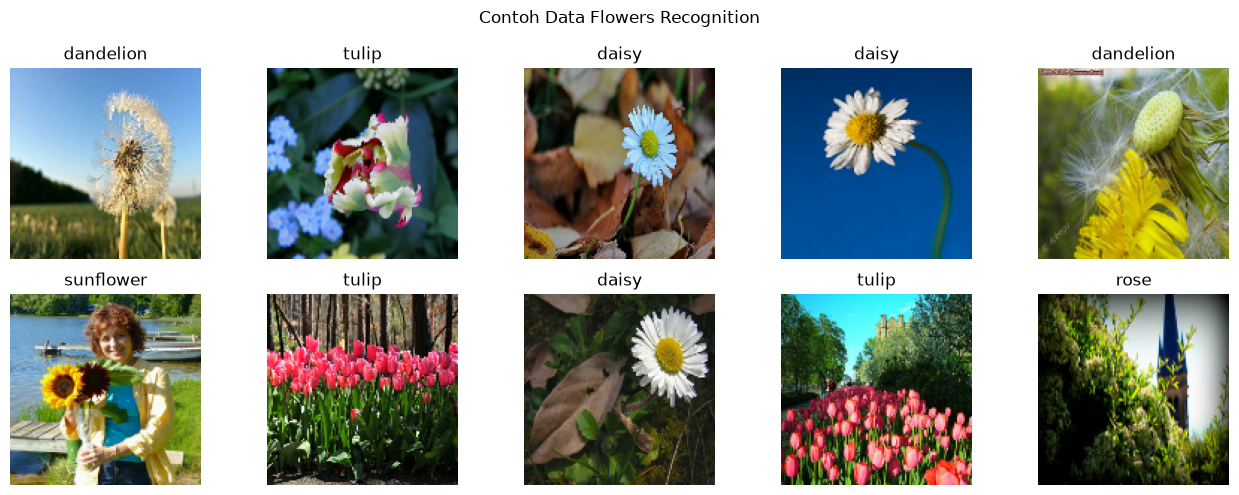

In [5]:
# Visualisasi 10 contoh citra dari data latih
fig, axes = plt.subplots(2, 5, figsize=(13, 5))
for images, labels in train_ds.take(1):
    for image, label, ax in zip(images[:10], labels[:10], axes.ravel()):
        ax.imshow(image.numpy().astype("uint8"))
        ax.set_title(CLASS_NAMES[int(label)])
        ax.axis("off")

plt.suptitle("Contoh Data Flowers Recognition")
plt.tight_layout()
plt.show()

In [6]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),
    tf.keras.layers.Rescaling(1.0 / 255),
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(len(CLASS_NAMES), activation="softmax"),
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,285 (12.61 MB)

 Trainable params: 3,305,285 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15


/usr/local/python/3.14.2/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
W0000 00:00:1794801666.959001    7182 cpu_allocator_impl.cc:174] Allocation of 65028096 exceeds 10% of free system memory.
W0000 00:00:1794801667.314708    7182 cpu_allocator_impl.cc:174] Allocation of 30482432 exceeds 10% of free system memory.
W0000 00:00:1794801667.652512    7182 cpu_allocator_impl.cc:174] Allocation of 23482368 exceeds 10% of free system memory.
W0000 00:00:1794801667.793813    7183 cpu_allocator_impl.cc:174] Allocation of 30482432 exceeds 10% of free system memory.
W0000 00:00:1794801667.887060    7183 cpu_allocator_impl.cc:174] Allocation of 25719552 exceeds 10% of free system memory.


108/108 ━━━━━━━━━━━━━━━━━━━━ 78s 706ms/step - accuracy: 0.4134 - loss: 1.3373 - val_accuracy: 0.4966 - val_loss: 1.1647
Epoch 2/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 73s 673ms/step - accuracy: 0.5744 - loss: 1.0654 - val_accuracy: 0.5235 - val_loss: 1.0761
Epoch 3/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 75s 694ms/step - accuracy: 0.6407 - loss: 0.9327 - val_accuracy: 0.5996 - val_loss: 0.9894
Epoch 4/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 78s 656ms/step - accuracy: 0.7113 - loss: 0.7829 - val_accuracy: 0.6376 - val_loss: 0.9484
Epoch 5/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 69s 634ms/step - accuracy: 0.7510 - loss: 0.6717 - val_accuracy: 0.6622 - val_loss: 0.9474
Epoch 6/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 65s 606ms/step - accuracy: 0.7999 - loss: 0.5465 - val_accuracy: 0.6242 - val_loss: 1.2916
Epoch 7/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 65s 601ms/step - accuracy: 0.8364 - loss: 0.4584 - val_accuracy: 0.6421 - val_loss: 1.1124
Epoch 8/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 83s 614ms/step - accuracy: 0.8590 - loss: 0.3810 - val

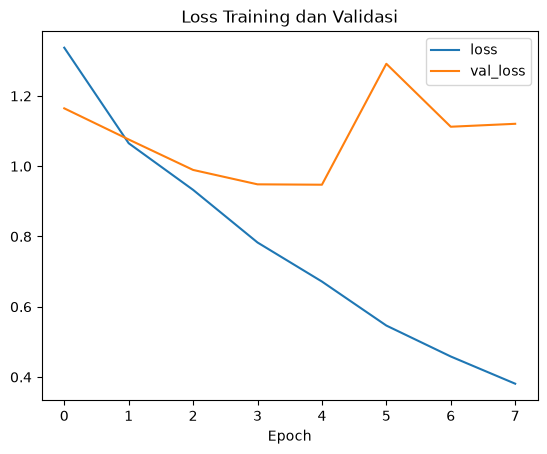

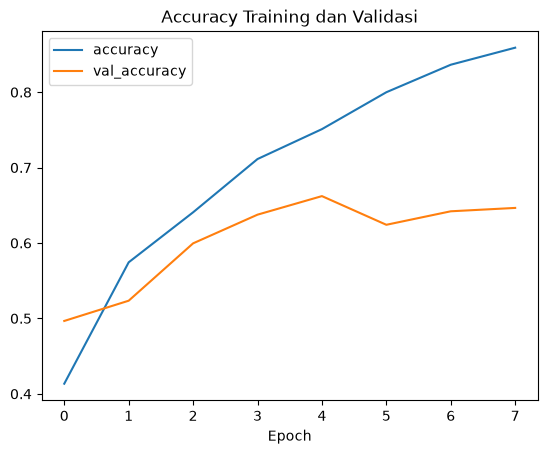

In [7]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stopping],
    verbose=1,
)

# Visualisasi kurva loss dan accuracy selama training
history_df = pd.DataFrame(history.history)

history_df[["loss", "val_loss"]].plot(title="Loss Training dan Validasi")
plt.xlabel("Epoch")
plt.show()

history_df[["accuracy", "val_accuracy"]].plot(title="Accuracy Training dan Validasi")
plt.xlabel("Epoch")
plt.show()

,Nilai
Accuracy,0.6971
Precision (weighted),0.7131
Recall (weighted),0.6971
F1-score (weighted),0.6962


Test loss: 0.8606

Classification Report:
              precision    recall  f1-score   support

       daisy     0.7647    0.7429    0.7536        70
   dandelion     0.6212    0.8817    0.7289        93
        rose     0.5574    0.5574    0.5574        61
   sunflower     0.8630    0.6848    0.7636        92
       tulip     0.7195    0.5900    0.6484       100

    accuracy                         0.6971       416
   macro avg     0.7052    0.6913    0.6904       416
weighted avg     0.7131    0.6971    0.6962       416



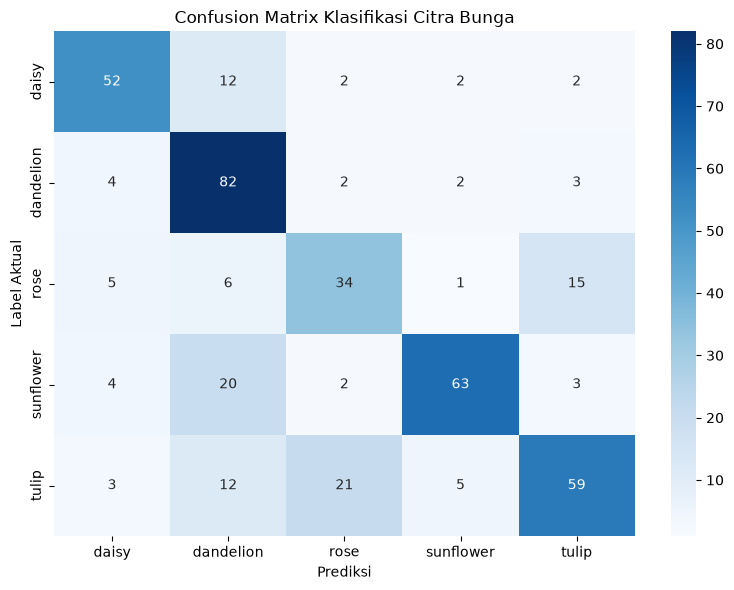

In [8]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
y_probability = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_probability, axis=1)

metrics_result = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision (weighted)": precision_score(y_test, y_pred, average="weighted", zero_division=0),
    "Recall (weighted)": recall_score(y_test, y_pred, average="weighted", zero_division=0),
    "F1-score (weighted)": f1_score(y_test, y_pred, average="weighted", zero_division=0),
}

metrics_df = pd.DataFrame.from_dict(metrics_result, orient="index", columns=["Nilai"])
metrics_df["Nilai"] = metrics_df["Nilai"].map(lambda value: f"{value:.4f}")
display(metrics_df)
print(f"Test loss: {test_loss:.4f}\n")

print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))

# Visualisasi Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
)
plt.title("Confusion Matrix Klasifikasi Citra Bunga")
plt.xlabel("Prediksi")
plt.ylabel("Label Aktual")
plt.tight_layout()
plt.show()